# Entrenamiento con fondos negativos

Reentrenamiento de YOLOv11n y YOLOv11s con `Data_final` más los fondos negativos de `2.2c_fondos_dataset.ipynb` (hojas vacías e impurezas inorgánicas y orgánicas, con la etiqueta vacía, un 10 % de cada conjunto). El objetivo es corregir el problema que mostró el diagnóstico: los modelos detectan como grano casi todas las impurezas.

**Diseño:**
- **Configuración:** la adoptada en la 2.2 (`configuracion_final.json`): SGD con `lr0 = 0.01`, lote 16, aumento por defecto, 1280 px, hasta 200 épocas con `patience = 50`.
- **Semillas:** las mismas del entrenamiento final (42, 7 y 28), de modo que cada modelo con fondos se compara con su par sin fondos.
- **Corridas:** 6, en la A100 de Colab, en dos sesiones:
  1. **semilla 42** de los dos modelos: da una primera lectura del efecto de los fondos;
  2. **semillas 7 y 28**, solo si la primera lectura no descarta los fondos. Si se adoptan, estas corridas son los nuevos modelos finales, y necesitan las 3 semillas, como en la 2.2.

  Cada sesión descarga sus resultados al terminar.
- **Métricas de validación:** sobre los granos de `valid` (las 98 imágenes de `Data_final`), comparables con las de la 2.2. El umbral de conteo es el de máximo F1 en esas imágenes.

**Regla de decisión, fijada antes de entrenar.** Para cada modelo, los fondos se adoptan si se cumplen las dos condiciones (medias de las 3 semillas; con solo la semilla 42, la lectura es preliminar):
1. los falsos positivos por imagen en las impurezas de `valid` bajan al menos un **90 %**;
2. el mAP50-95 en los granos de `valid` no cae más de **0.005**, el mismo margen que usó la 2.2 para considerar una diferencia.

El conjunto de evaluación de `datos/fondos` (impurezas de las sesiones del test y hojas no usadas) no interviene en la decisión: mide al final el efecto sobre imágenes nunca vistas. El test de granos no se usa.

In [1]:
MODELOS_SESION = ('yolo11n', 'yolo11s')   # opcional: un solo modelo por sesión para acortarla
SEMILLAS_SESION = (42,)                   # primera sesión: (42,); segunda: (7, 28)

In [2]:
# --- Entorno: local (análisis) o Colab (entrenamiento) ---
import os, sys, glob, shutil, subprocess, zipfile
from pathlib import Path

FASE = 'fondos'
PLATAFORMA = 'colab' if 'COLAB_RELEASE_TAG' in os.environ else 'kaggle' if 'KAGGLE_KERNEL_RUN_TYPE' in os.environ else 'local'
os.environ['YOLO_VERBOSE'] = 'False'   # sin barras de progreso de Ultralytics: en Colab, la página se congela
if PLATAFORMA == 'local':
    RAIZ = Path.cwd()
else:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'ultralytics==8.4.174', 'albumentations==2.0.8'], check=True)
    base = Path('/kaggle/working') if PLATAFORMA == 'kaggle' else Path('/content')
    RAIZ = base / 'maiz-yolo11' / 'oe2'
    if not (RAIZ / 'comun_oe2.py').exists():
        if PLATAFORMA == 'colab':   # el paquete está en Google Drive, que solo se lee
            from google.colab import drive
            drive.mount('/content/drive')
        origen = '/kaggle/input' if PLATAFORMA == 'kaggle' else '/content/drive/MyDrive'
        paquete = glob.glob(f'{origen}/oe2_fondos_nube*.zip') or glob.glob(f'{origen}/**/oe2_fondos_nube*.zip', recursive=True)
        assert paquete, 'No se encontró oe2_fondos_nube.zip'
        zipfile.ZipFile(paquete[0]).extractall(base)
os.chdir(RAIZ); sys.path.insert(0, str(RAIZ))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display
import comun_oe2 as E

C = E.C
if isinstance(MODELOS_SESION, str):   # ('yolo11s') sin coma es un texto, no una tupla
    MODELOS_SESION = (MODELOS_SESION,)
if isinstance(SEMILLAS_SESION, int):  # (42) sin coma es un número, no una tupla
    SEMILLAS_SESION = (SEMILLAS_SESION,)
assert set(MODELOS_SESION) <= set(E.MODELOS), f'MODELOS_SESION debe contener {E.MODELOS}'
assert set(SEMILLAS_SESION) <= set(E.SEMILLAS_FINAL), f'SEMILLAS_SESION debe contener {E.SEMILLAS_FINAL}'
C.estilo()
REGISTRO, RUNS, TRABAJO = E.REGISTRO, E.RUNS, E.TRABAJO   # oe2/resultados/experimentos/fondos.csv, runs/oe2/, trabajo/oe2/
SALIDA = RAIZ / 'salida' / '2.2c_fondos'
if PLATAFORMA != 'local':
    # Descargas de una sesión anterior de esta fase, subidas a /content: se reanuda desde ahí
    for previo in glob.glob(str(base / 'oe2_fondos_s*.zip')):
        E.integrar_descarga(previo)
CFG = {m: {k: c[k] for k in ('optimizer', 'lr0', 'batch', 'aumento')} for m, c in E.config_final().items()}
REDUCCION_FP_MIN, PERDIDA_MAP_MAX = 0.90, E.GANANCIA_MIN
if PLATAFORMA != 'local':
    assert torch.cuda.is_available(), 'No hay GPU: Entorno de ejecución > Cambiar tipo de entorno > A100'
    if 'A100' not in torch.cuda.get_device_name(0):
        print('AVISO: la GPU no es una A100; las corridas del OE2 deben hacerse todas en la misma GPU.')
print(f'Plataforma: {PLATAFORMA} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else "ninguna"} | '
      f'configuración: {CFG}')

Plataforma: local | GPU: NVIDIA GeForce RTX 3060 Laptop GPU | configuración: {'yolo11n': {'optimizer': 'SGD', 'lr0': 0.01, 'batch': 16, 'aumento': 'A'}, 'yolo11s': {'optimizer': 'SGD', 'lr0': 0.01, 'batch': 16, 'aumento': 'A'}}


## 1. Corridas

Solo se ejecuta en la nube. Las corridas ya registradas se omiten, así que la sesión puede reanudarse.

In [3]:
import time

def entrenar(modelo, cfg, semilla, particion):
    print(f'-> {E.id_corrida(modelo, cfg, semilla, particion)}', flush=True)
    f = E.entrenar(modelo, cfg, semilla, particion, FASE, RUNS, REGISTRO, TRABAJO)
    print(f"   mAP50-95 {f['mAP50_95']:.4f} | mejor época {f['mejor_epoca']} de {f['epocas_ejecutadas']} | "
          f"{f['minutos']} min | VRAM {f['vram_gb']} GB", flush=True)
    return f

if PLATAFORMA != 'local':
    t0, antes = time.time(), len(E.leer_registro(REGISTRO))
    try:
        for modelo in MODELOS_SESION:
            for semilla in SEMILLAS_SESION:
                E.obtener_map(REGISTRO, modelo, CFG[modelo], semilla, 'fondos', entrenar)
    except Exception:   # una corrida fallida no impide descargar las ya completadas
        import traceback; traceback.print_exc()
        print('La sesión se interrumpió: se descargan las corridas completadas; al volver a ejecutar, se reanuda.')
    print(f'{len(E.leer_registro(REGISTRO)) - antes} corridas nuevas en {(time.time() - t0) / 3600:.1f} h')

In [4]:
# Descarga: el CSV de la fase y las carpetas de las corridas de la sesión (best.pt, curvas, argumentos),
# con las rutas del repositorio. En local se incorpora con E.integrar_descarga.
if PLATAFORMA != 'local':
    reg = E.leer_registro(REGISTRO)
    sufijo = ('' if set(MODELOS_SESION) == set(E.MODELOS) else '_' + '_'.join(MODELOS_SESION)) + \
             '_s' + '_'.join(map(str, SEMILLAS_SESION))
    destino = base / f'oe2_{FASE}{sufijo}.zip'
    with zipfile.ZipFile(destino, 'w', zipfile.ZIP_DEFLATED) as z:
        z.write(REGISTRO / f'{FASE}.csv', (REGISTRO / f'{FASE}.csv').relative_to(E.REPO))
        nuevas = (reg['fase'] == FASE) & reg['modelo'].isin(MODELOS_SESION) & reg['semilla'].isin(SEMILLAS_SESION)
        for rid in reg.loc[nuevas, 'id']:
            for f in (RUNS / rid).rglob('*'):
                if f.is_file():   # los .pt ya están comprimidos
                    z.write(f, f.relative_to(E.REPO), compress_type=zipfile.ZIP_STORED if f.suffix == '.pt' else zipfile.ZIP_DEFLATED)
    print(f'{destino} ({destino.stat().st_size / 1e6:.0f} MB)')
    if PLATAFORMA == 'colab':
        from google.colab import files
        files.download(str(destino))

## 2. Análisis

Se ejecuta en local, después de incorporar cada descarga con `E.integrar_descarga('oe2_fondos_s<semillas>.zip')`. Se compara cada modelo con fondos con su par sin fondos de la 2.2, con las mismas semillas. Con solo la semilla 42, la decisión es preliminar y no se guarda la configuración.

In [5]:
reg = E.leer_registro(REGISTRO)
con = reg[reg['particion'] == 'fondos']
semillas = sorted(int(s) for s in con['semilla'].unique())
sin = reg[(reg['particion'] == 'final') & reg['semilla'].isin(semillas)]   # pares sin fondos, mismas semillas
ETIQUETA = {'yolo11n': 'YOLOv11n', 'yolo11s': 'YOLOv11s'}
listo = len(con) > 0 and all((con['modelo'] == m).sum() == len(semillas) for m in E.MODELOS)
completo = listo and len(semillas) == len(E.SEMILLAS_FINAL)
print(f'Corridas con fondos: {len(con)} (semillas {semillas})' +
      ('' if completo else ' -> lectura preliminar' if listo else ' -> faltan modelos'))
VERSIONES = {'sin fondos': sin, 'con fondos': con}
CONF = {v: d.groupby('modelo')['conf_f1'].median() for v, d in VERSIONES.items()}   # umbral de conteo de cada versión
pesos = lambda rid: RUNS / rid / 'weights' / 'best.pt'

Corridas con fondos: 6 (semillas [7, 28, 42])


### 2.1. Granos de `valid`

Métricas de detección y de aplicación en las 98 imágenes con granos. Diferencia: con fondos − sin fondos, emparejada por semilla.

In [6]:
if listo:
    metr = ['mAP50_95', 'mAP50', 'mAP75', 'precision', 'recall', 'f1_max', 'conf_f1', 'mae_conteo'] + \
           [c for c in reg.columns if c.startswith('acierto_')]
    filas = []
    for modelo in E.MODELOS:
        a = sin[sin.modelo == modelo].set_index('semilla')[metr]
        b = con[con.modelo == modelo].set_index('semilla')[metr]
        d = (b - a.loc[b.index])
        filas.append(pd.DataFrame({'sin fondos': a.mean(), 'con fondos': b.mean(), 'diferencia': d.mean(),
                                   'a favor': (d > 0).sum(), 'desv. diferencia': d.std()}).assign(modelo=ETIQUETA[modelo]))
    granos_valid = pd.concat(filas).set_index('modelo', append=True).swaplevel().round(4)
    display(granos_valid)

sin fondos  con fondos  diferencia  a favor  \
modelo                                                                    
YOLOv11n mAP50_95               0.7128      0.7272      0.0144        3   
         mAP50                  0.9603      0.9646      0.0043        1   
         mAP75                  0.8437      0.8687      0.0250        3   
         precision              0.8629      0.8790      0.0162        2   
         recall                 0.9210      0.9205     -0.0005        2   
         f1_max                 0.8875      0.8969      0.0095        2   
         conf_f1                0.3984      0.5152      0.1168        3   
         mae_conteo             0.4762      0.3605     -0.1156        1   
         acierto_Broken         0.9275      0.8941     -0.0333        0   
         acierto_Damage         0.9308      0.9253     -0.0055        1   
         acierto_Fungus         0.9803      0.9892      0.0089        2   
         acierto_Healthy        0.8399      0.8649      0.0250        2   
         acierto_Immature       0.7528      0.7694      0.0167        1   
         acierto_Shriveled      0.9677      0.9365     -0.0312        0   
         acierto_Weeveled       0.8924      0.9138      0.0213        1   
YOLOv11s mAP50_95               0.7207      0.7291      0.0084        3   
         mAP50                  0.9580      0.9629      0.0050        3   
         mAP75                  0.8556      0.8711      0.0155        2   
         precision              0.8853      0.8764     -0.0089        2   
         recall                 0.9103      0.9287      0.0185        2   
         f1_max                 0.8955      0.8988      0.0034        2   
         conf_f1                0.4535      0.4194     -0.0340        1   
         mae_conteo             0.3980      0.4626      0.0646        2   
         acierto_Broken         0.8431      0.8902      0.0471        2   
         acierto_Damage         0.8470      0.9326      0.0856        2   
         acierto_Fungus         0.9669      0.9803      0.0134        2   
         acierto_Healthy        0.8974      0.8571     -0.0403        1   
         acierto_Immature       0.8375      0.7889     -0.0486        1   
         acierto_Shriveled      0.9184      0.9688      0.0504        3   
         acierto_Weeveled       0.8672      0.8983      0.0310        2   

                            desv. diferencia  
modelo                                        
YOLOv11n mAP50_95                     0.0066  
         mAP50                        0.0156  
         mAP75                        0.0137  
         precision                    0.0670  
         recall                       0.0149  
         f1_max                       0.0343  
         conf_f1                      0.0252  
         mae_conteo                   0.1739  
         acierto_Broken               0.0577  
         acierto_Damage               0.0304  
         acierto_Fungus               0.0327  
         acierto_Healthy              0.0599  
         acierto_Immature             0.0811  
         acierto_Shriveled            0.0258  
         acierto_Weeveled             0.1656  
YOLOv11s mAP50_95                     0.0065  
         mAP50                        0.0046  
         mAP75                        0.0258  
         precision                    0.0310  
         recall                       0.0174  
         f1_max                       0.0141  
         conf_f1                      0.0507  
         mae_conteo                   0.0648  
         acierto_Broken               0.0765  
         acierto_Damage               0.0890  
         acierto_Fungus               0.0281  
         acierto_Healthy              0.0954  
         acierto_Immature             0.2125  
         acierto_Shriveled            0.0680  
         acierto_Weeveled             0.1579

### 2.2. Fondos de `valid` y decisión

Detecciones en las imágenes sin granos de `valid` (todas son falsos positivos), con el umbral de conteo de cada versión.

In [7]:
def falsos_positivos(imagenes, anotaciones=None):
    """Detecciones por imagen y, si hay anotaciones de impurezas, qué fracción de ellas se detecta como grano."""
    filas = []
    for version, d in VERSIONES.items():
        for _, f in d.iterrows():
            pred = E.predecir(pesos(f['id']), imagenes, CONF[version][f['modelo']])
            for stem, (pb, pc, pf) in pred.items():
                tipo = 'hoja' if stem.startswith('hoja_') else stem.split('_')[1].capitalize()
                fila = {'versión': version, 'modelo': ETIQUETA[f['modelo']], 'semilla': int(f['semilla']), 'stem': stem,
                        'tipo': tipo, 'detecciones': len(pb)}
                if anotaciones is not None and len(anotaciones[stem]):
                    pares, _ = E.emparejar(anotaciones[stem], pb)
                    fila.update(objetos=len(anotaciones[stem]), detectados=len(pares))
                filas.append(fila)
    return pd.DataFrame(filas)

if listo:
    fv = falsos_positivos(sorted((E.FONDOS / 'valid' / 'images').glob('*.jpg')))
    tabla = fv.groupby(['modelo', 'tipo', 'versión']).detecciones.mean().unstack('versión')[['sin fondos', 'con fondos']]
    display(tabla.round(2).rename_axis(columns='detecciones por imagen'))
    decision = {}
    for modelo in E.MODELOS:
        imp = fv[(fv.modelo == ETIQUETA[modelo]) & (fv.tipo != 'hoja')].groupby('versión').detecciones.mean()
        reduccion = 1 - imp['con fondos'] / imp['sin fondos']
        dmap = granos_valid.loc[(ETIQUETA[modelo], 'mAP50_95'), 'diferencia']
        decision[modelo] = {'reduccion_fp': round(float(reduccion), 4), 'diferencia_mAP50_95': round(float(dmap), 4),
                            'adoptada': bool(reduccion >= REDUCCION_FP_MIN and dmap >= -PERDIDA_MAP_MAX)}
        veredicto = 'se adoptan los fondos' if decision[modelo]['adoptada'] else 'no se adoptan los fondos'
        print(f"{ETIQUETA[modelo]}: falsos positivos en impurezas de valid {imp['sin fondos']:.1f} -> {imp['con fondos']:.1f} "
              f"por imagen (−{reduccion:.0%}); mAP50-95 en granos {dmap:+.4f} -> "
              f"{veredicto if completo else 'lectura preliminar: ' + veredicto}")

detecciones por imagen  sin fondos  con fondos
modelo   tipo                                 
YOLOv11n Inorganic           30.75        0.00
         Organic             38.50        0.67
         hoja                 0.00        0.00
YOLOv11s Inorganic           30.50        0.00
         Organic             32.67        0.42
         hoja                 0.00        0.00

YOLOv11n: falsos positivos en impurezas de valid 34.6 -> 0.3 por imagen (−99%); mAP50-95 en granos +0.0144 -> se adoptan los fondos
YOLOv11s: falsos positivos en impurezas de valid 31.6 -> 0.2 por imagen (−99%); mAP50-95 en granos +0.0084 -> se adoptan los fondos


### 2.3. Conjunto de evaluación

Impurezas de las sesiones del test y hojas no usadas en el entrenamiento: imágenes nunca vistas por ninguna versión. Para las impurezas, también la fracción de objetos detectados como grano (IoU ≥ 0.5).

imágenes            detecciones_por_imagen             \
versión            con fondos sin fondos             con fondos sin fondos   
modelo   tipo                                                                
YOLOv11n Inorganic         20         20                  0.150     33.367   
         Organic           13         13                  0.051     41.205   
         hoja              10         10                  0.000      0.000   
YOLOv11s Inorganic         20         20                  0.050     33.350   
         Organic           13         13                  0.000     34.974   
         hoja              10         10                  0.000      0.000   

                   detectados como grano             
versión                       con fondos sin fondos  
modelo   tipo                                        
YOLOv11n Inorganic                 0.005      0.991  
         Organic                   0.001      0.968  
         hoja                        NaN        NaN  
YOLOv11s Inorganic                 0.001      0.994  
         Organic                   0.000      0.941  
         hoja                        NaN        NaN

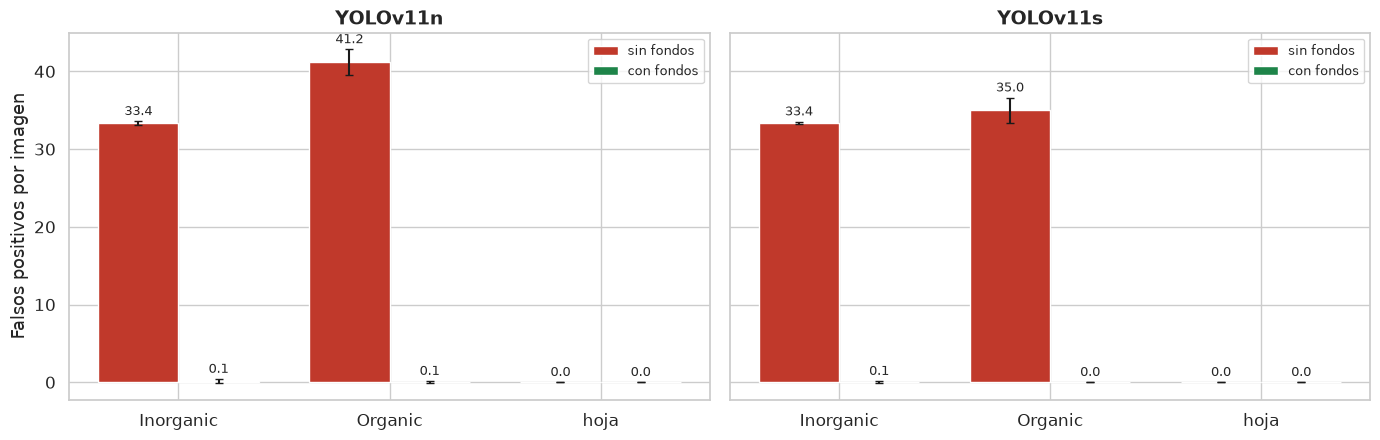

In [8]:
EVAL = sorted((E.FONDOS / 'evaluacion' / 'images').glob('*.jpg'))

def anotaciones_eval(p):
    img_h, img_w = cv2.imread(str(p)).shape[:2]
    c, _ = C.leer_yolo(E.FONDOS / 'evaluacion' / 'impurezas' / f'{p.stem}.txt')
    c = np.array(c, float).reshape(-1, 4)
    return np.stack([(c[:, 0] - c[:, 2] / 2) * img_w, (c[:, 1] - c[:, 3] / 2) * img_h,
                     (c[:, 0] + c[:, 2] / 2) * img_w, (c[:, 1] + c[:, 3] / 2) * img_h], 1)

import cv2
if listo:
    ANOT = {p.stem: anotaciones_eval(p) for p in EVAL}
    fe = falsos_positivos(EVAL, ANOT)
    t = fe.groupby(['modelo', 'tipo', 'versión']).agg(imágenes=('stem', 'nunique'), detecciones_por_imagen=('detecciones', 'mean'),
                                                       objetos=('objetos', 'sum'), detectados=('detectados', 'sum'))
    t['detectados como grano'] = (t['detectados'] / t['objetos']).where(t['objetos'] > 0)
    display(t.drop(columns=['objetos', 'detectados']).unstack('versión').round(3))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
    for ax, modelo in zip(axes, ETIQUETA.values()):
        m = fe[fe.modelo == modelo].groupby(['tipo', 'versión']).detecciones.mean().unstack('versión')[['sin fondos', 'con fondos']]
        s = fe[fe.modelo == modelo].groupby(['tipo', 'versión', 'semilla']).detecciones.mean().groupby(['tipo', 'versión']).std().unstack('versión')
        x = np.arange(len(m)); w = 0.38
        for k, (v, color) in enumerate((('sin fondos', E.MAL), ('con fondos', E.OK))):
            ax.bar(x + (k - 0.5) * w, m[v], w, yerr=s[v].fillna(0), capsize=3, color=color, label=v)
            for xi, val, err in zip(x, m[v], s[v].fillna(0)):
                ax.text(xi + (k - 0.5) * w, val + err + 0.8, f'{val:.1f}', ha='center', fontsize=9)
        ax.set_xticks(x); ax.set_xticklabels(m.index); ax.set_title(modelo); ax.legend(fontsize=9)
    axes[0].set_ylabel('Falsos positivos por imagen')
    C.guardar(SALIDA, 'evaluacion_falsos_positivos.png')

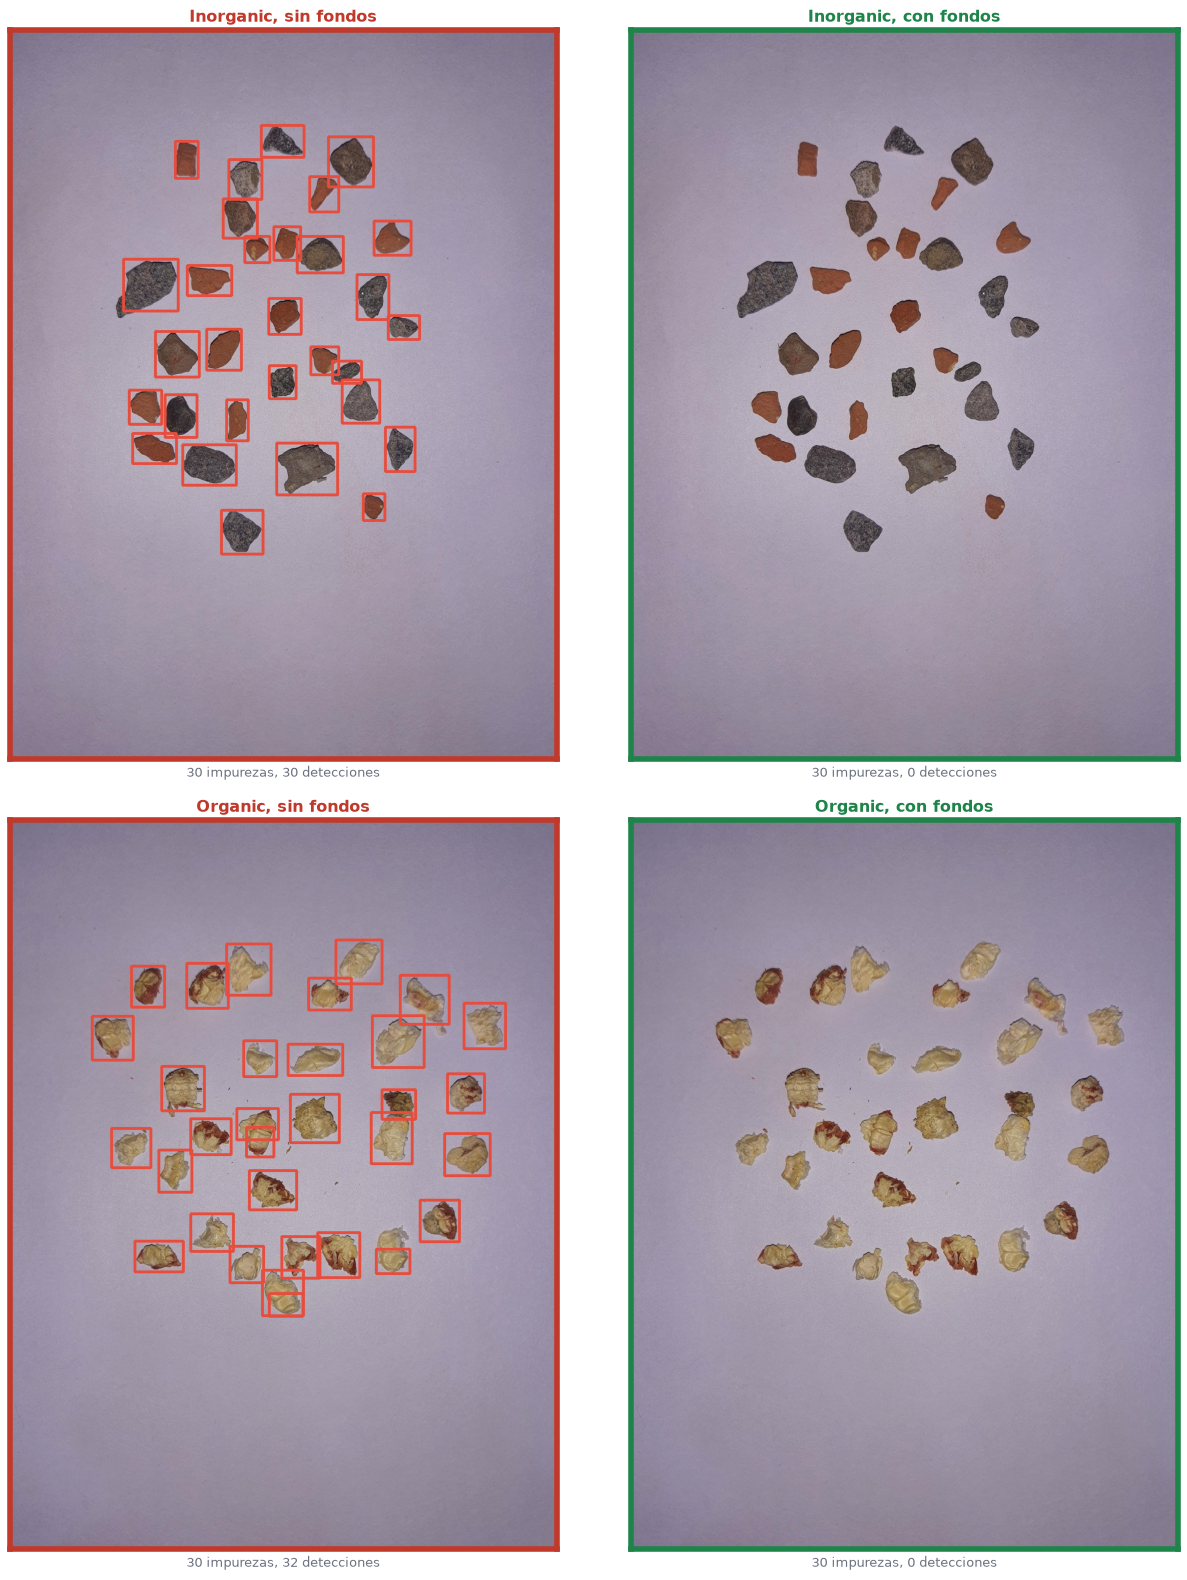

In [9]:
# Una impureza inorgánica y una orgánica de evaluación, sin y con fondos (YOLOv11s, primera semilla)
if listo:
    ejemplos = [next(p for p in EVAL if p.stem.startswith(f'imp_{t}')) for t in ('inorganic', 'organic')]
    fig, axes = plt.subplots(2, 2, figsize=(13, 16))
    for fila, p in zip(axes, ejemplos):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        for ax, (version, d) in zip(fila, VERSIONES.items()):
            f = d[(d.modelo == 'yolo11s') & (d.semilla == semillas[0])].iloc[0]
            pb, pc, _ = E.predecir(pesos(f['id']), [p], CONF[version]['yolo11s'])[p.stem]
            vista = E.dibujar(E.dibujar(img, pb[pc == 0], E.CAJA_OK, 4), pb[pc == 1], E.CAJA_MAL, 4)
            E.mostrar(ax, vista, f"{p.stem.split('_')[1].capitalize()}, {version}",
                      f'{len(ANOT[p.stem])} impurezas, {len(pb)} detecciones', estado='ok' if version == 'con fondos' else 'mal')
    C.guardar(SALIDA, 'evaluacion_ejemplos.png')

### 2.4. Convergencia y configuración

Curvas de mAP50-95 en `valid` por época de las corridas con fondos (el `valid` del entrenamiento incluye los fondos). Con las 3 semillas, la configuración y la decisión se guardan en `resultados/configuracion_fondos.json`.

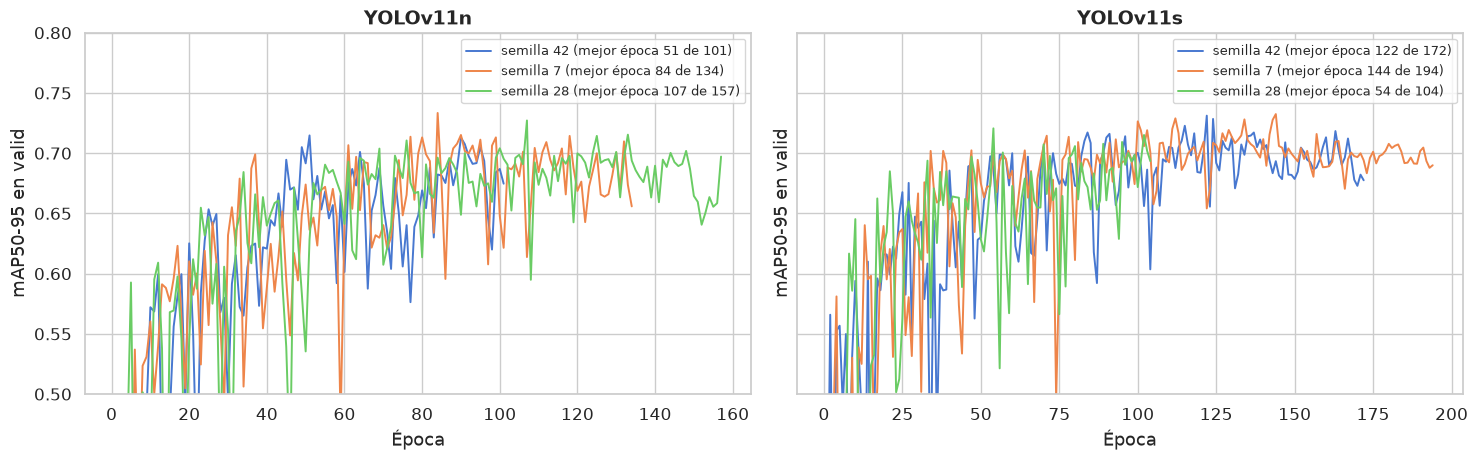

{
 "yolo11n": {
  "optimizer": "SGD",
  "lr0": 0.01,
  "batch": 16,
  "aumento": "A",
  "fondos": true,
  "conf_conteo": 0.506,
  "reduccion_fp": 0.9904,
  "diferencia_mAP50_95": 0.0144,
  "adoptada": true,
  "pesos": [
   "runs/oe2/yolo11n_SGD_lr0.01_b16_augA_s42_fondos/weights/best.pt",
   "runs/oe2/yolo11n_SGD_lr0.01_b16_augA_s7_fondos/weights/best.pt",
   "runs/oe2/yolo11n_SGD_lr0.01_b16_augA_s28_fondos/weights/best.pt"
  ]
 },
 "yolo11s": {
  "optimizer": "SGD",
  "lr0": 0.01,
  "batch": 16,
  "aumento": "A",
  "fondos": true,
  "conf_conteo": 0.417,
  "reduccion_fp": 0.9934,
  "diferencia_mAP50_95": 0.0084,
  "adoptada": true,
  "pesos": [
   "runs/oe2/yolo11s_SGD_lr0.01_b16_augA_s42_fondos/weights/best.pt",
   "runs/oe2/yolo11s_SGD_lr0.01_b16_augA_s7_fondos/weights/best.pt",
   "runs/oe2/yolo11s_SGD_lr0.01_b16_augA_s28_fondos/weights/best.pt"
  ]
 }
}


In [10]:
if listo:
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
    for ax, modelo in zip(axes, E.MODELOS):
        for _, f in con[con['modelo'] == modelo].iterrows():
            curva = pd.read_csv(RUNS / f['id'] / 'results.csv'); curva.columns = [c.strip() for c in curva.columns]
            linea, = ax.plot(curva['epoch'], curva['metrics/mAP50-95(B)'], lw=1.4,
                             label=f"semilla {int(f['semilla'])} (mejor época {int(f['mejor_epoca'])} de {int(f['epocas_ejecutadas'])})")
        ax.set_ylim(0.5, 0.8); ax.set_title(ETIQUETA[modelo]); ax.set_xlabel('Época'); ax.set_ylabel('mAP50-95 en valid'); ax.legend(fontsize=9)
    C.guardar(SALIDA, 'convergencia_fondos.png')

if completo:
    config = {m: {**CFG[m], 'fondos': True, 'conf_conteo': round(float(CONF['con fondos'][m]), 3), **decision[m],
                  'pesos': [str((RUNS / i / 'weights' / 'best.pt').relative_to(E.REPO)) for i in con[con['modelo'] == m]['id']]} for m in E.MODELOS}
    (RAIZ / 'resultados' / 'configuracion_fondos.json').write_text(json.dumps(config, indent=1, ensure_ascii=False))
    print(json.dumps(config, indent=1, ensure_ascii=False))

## 3. Paquete para la nube

Se genera en local: `nube/oe2_fondos_nube.zip`, con `Data_final`, los fondos de `train` y `valid`, la configuración final de la 2.2 y el código. Se copia a Google Drive, que solo se lee.

In [11]:
if PLATAFORMA == 'local':
    archivos = [C.RAIZ / 'comun.py', C.RAIZ / 'resultados' / 'particion.json', RAIZ / 'comun_oe2.py',
                RAIZ / '2.2c_fondos_entrenamiento.ipynb', RAIZ / 'resultados' / 'configuracion_final.json', E.FONDOS / 'data.yaml']
    archivos += sorted(p for p in E.FINAL.rglob('*') if p.is_file() and p.suffix != '.cache')
    archivos += sorted(p for c in ('train', 'valid') for p in (E.FONDOS / c).rglob('*') if p.is_file() and p.suffix != '.cache')
    destino = C.NUBE / 'oe2_fondos_nube.zip'
    destino.parent.mkdir(exist_ok=True)
    with zipfile.ZipFile(destino, 'w') as z:
        for p in archivos:
            z.write(p, Path(E.REPO.name) / p.relative_to(E.REPO), compress_type=zipfile.ZIP_STORED if p.suffix == '.jpg' else zipfile.ZIP_DEFLATED)
    print(f'{destino} ({destino.stat().st_size / 1e6:.0f} MB, {len(archivos)} archivos)')

/home/ismael/Documents/Tesis/maiz-yolo11/nube/oe2_fondos_nube.zip (169 MB, 1644 archivos)
